# 1. Exploração de Dados — Thermal Predictor

Este notebook gera os gráficos exigidos pela Seção 4.2.1 da documentação (ver [`documents/documentacao.md`](../documents/documentacao.md)): pelo menos 3 visualizações de relações entre colunas do dataset.

Fonte: `data/dataset_long.csv` (formato tidy, uma linha por combinação Run x TC), gerado por [`00_reestruturacao_planilha.ipynb`](00_reestruturacao_planilha.ipynb). Classificação numérica/categórica de referência: [`classify_columns.ipynb`](classify_columns.ipynb).

As colunas escolhidas para os gráficos foram as que apresentam variância real confirmada na classificação de colunas (`key_area`, `housing`, `blower_direction`, `run_case`, `active_limit`, `temp`). Ficaram de fora `board_position` (quase constante: 3843 "Center" vs. 222 "Right", só 5,5% da amostra na categoria minoritária) e colunas de identificador (`run_id`, `tc_number`, `tc_name`).


## 1. Carregar dados e configurar estilo

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import os

df = pd.read_csv('../data/dataset_long.csv')

sns.set_theme(style='whitegrid')
FIG_DIR = '../assets/graficos'
os.makedirs(FIG_DIR, exist_ok=True)

df.shape

(4065, 14)

### Limpeza mínima para plotagem

Duas colunas usadas nos gráficos têm sujeira de formatação que precisa ser normalizada antes de plotar (o tratamento completo, para fins de modelagem, fica para a Seção 4.2.2):

- `active_limit`: majoritariamente numérica, mas com sujeira de dois tipos:
  1. 1 valor residual de texto (`"Monitor (150 C)"`, sensor sem limite de segurança definido), tratado com `pd.to_numeric(errors='coerce')`.
  2. **Achado novo**: 8 sensores (302 linhas, 7,4% da base) têm `active_limit = 1000`, fisicamente implausível para os componentes em questão (blower, ducts — os demais limites reais vão de 60 a 220°C). É outro placeholder de "sem limite definido", igual em espírito ao `"Monitor (150 C)"`, só que numérico — e por isso não aparece como erro de conversão. Tratado como sentinela e excluído do cálculo de excedência do Gráfico 3.
- `blower_direction`: mesma categoria grafada de formas diferentes (`"To back"` vs. `"To Back"`, `"To Front"` vs. `"To front"`) — normalizada com `.str.strip().str.title()`.


In [2]:
df['active_limit_num'] = pd.to_numeric(df['active_limit'], errors='coerce')

# active_limit == 1000 e um placeholder de "sem limite definido", nao um limite
# real (nenhum outro limite passa de 220 C) -> tratado como sentinela, nao como dado.
SENTINEL_LIMIT = 1000
n_sentinel = (df['active_limit_num'] == SENTINEL_LIMIT).sum()
df.loc[df['active_limit_num'] == SENTINEL_LIMIT, 'active_limit_num'] = pd.NA

df['blower_direction_norm'] = df['blower_direction'].str.strip().str.title()
df['housing_norm'] = df['housing'].str.strip()

n_naotexto = df['active_limit'].notna().sum() - pd.to_numeric(df['active_limit'], errors='coerce').notna().sum()
print(f"active_limit: {n_naotexto} valores nao numericos + {n_sentinel} sentinelas (=1000) descartados")
df['blower_direction_norm'].value_counts()

active_limit: 56 valores nao numericos + 302 sentinelas (=1000) descartados


blower_direction_norm
To Front    2853
To Back     1212
Name: count, dtype: int64

## 2. Gráfico 1 — Temperatura por área-chave (`temp` x `key_area`)

Boxplot da distribuição de `temp` em cada `key_area`. Mostra que as áreas do fogão operam em regimes térmicos bem diferentes entre si — informação de base para qualquer hipótese que envolva a localização física do sensor.


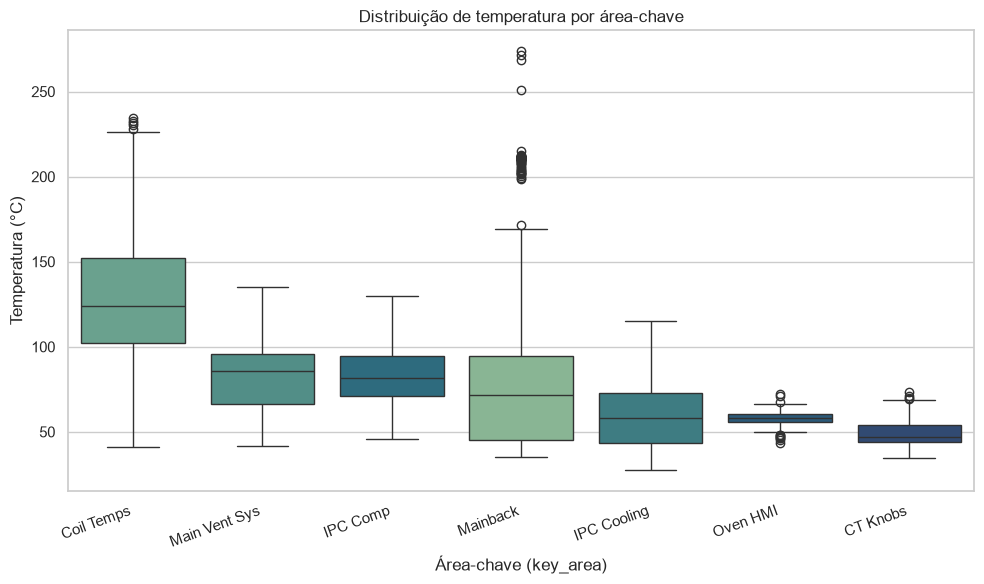

In [3]:
order = df.groupby('key_area')['temp'].median().sort_values(ascending=False).index

fig, ax = plt.subplots(figsize=(10, 6))
sns.boxplot(data=df, x='key_area', y='temp', order=order, hue='key_area',
            palette='crest', legend=False, ax=ax)
ax.set_xlabel('Área-chave (key_area)')
ax.set_ylabel('Temperatura (°C)')
ax.set_title('Distribuição de temperatura por área-chave')
plt.xticks(rotation=20, ha='right')
plt.tight_layout()
plt.savefig(f'{FIG_DIR}/temp_por_area.png', dpi=150)
plt.show()

## 3. Gráfico 2 — Temperatura média por `housing` x `blower_direction`

Gráfico de barras agrupado com a temperatura média por combinação de `housing` (estado da carcaça) e `blower_direction` (direção do fluxo de ar do soprador, já normalizada). Testa se a direção do ar e o tipo de housing interagem no efeito térmico.


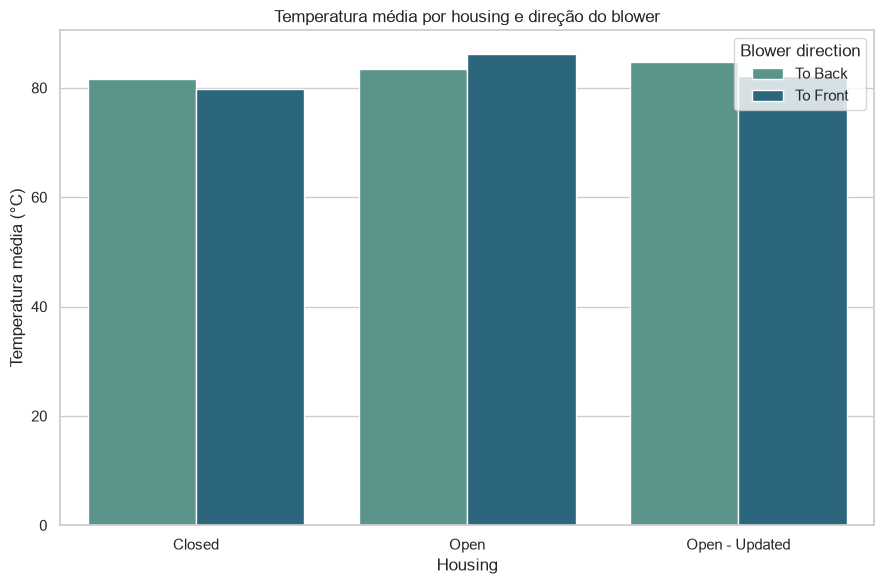

In [4]:
grouped = (
    df.groupby(['housing_norm', 'blower_direction_norm'])['temp']
    .mean()
    .reset_index()
)

fig, ax = plt.subplots(figsize=(9, 6))
sns.barplot(data=grouped, x='housing_norm', y='temp', hue='blower_direction_norm',
            palette='crest', ax=ax)
ax.set_xlabel('Housing')
ax.set_ylabel('Temperatura média (°C)')
ax.set_title('Temperatura média por housing e direção do blower')
ax.legend(title='Blower direction')
plt.tight_layout()
plt.savefig(f'{FIG_DIR}/temp_housing_blower.png', dpi=150)
plt.show()

## 4. Gráfico 3 — Temperatura vs. limite de engenharia (`temp` x `active_limit`)

Scatter plot de `temp` vs. `active_limit_num`, destacando em vermelho os pontos em que a temperatura medida ultrapassa o limite de engenharia do sensor (`temp > active_limit`). Esse é o gráfico mais ligado ao problema de negócio: mostra quantos componentes estouram o limite térmico projetado. Não existe uma coluna `exceeds_limit` pronta no dataset — ela é calculada aqui a partir de `temp` e `active_limit`, já excluindo os sentinelas (texto residual e `active_limit = 1000`) tratados na limpeza acima.


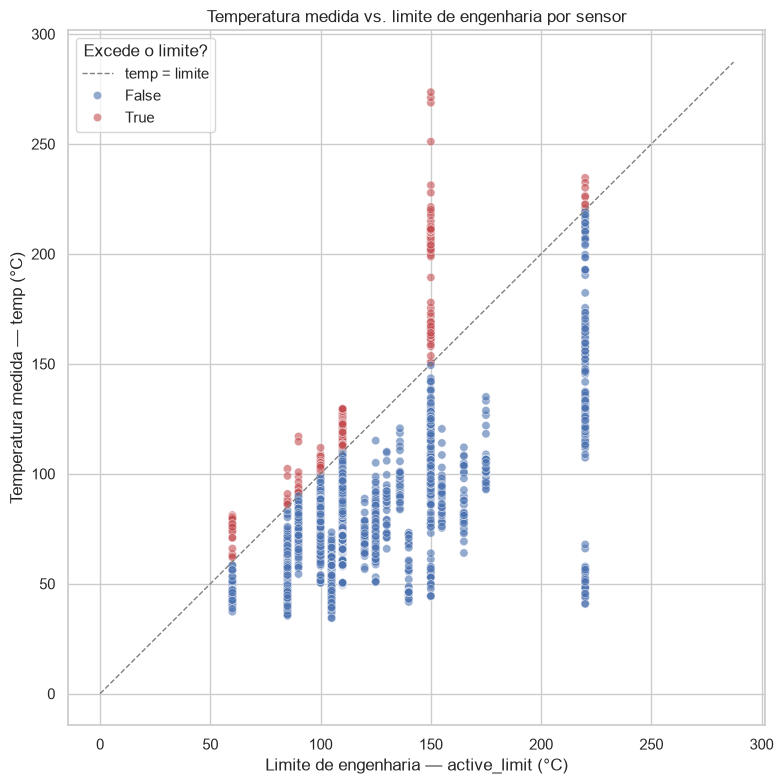

309 de 3707 leituras (8.3%) excedem o limite de engenharia


In [5]:
plot_df = df.dropna(subset=['active_limit_num']).copy()
plot_df['exceeds'] = plot_df['temp'] > plot_df['active_limit_num']

fig, ax = plt.subplots(figsize=(8, 8))
lim = max(plot_df['temp'].max(), plot_df['active_limit_num'].max()) * 1.05
ax.plot([0, lim], [0, lim], linestyle='--', color='gray', linewidth=1, label='temp = limite')
sns.scatterplot(
    data=plot_df, x='active_limit_num', y='temp', hue='exceeds',
    palette={False: '#4C72B0', True: '#C44E52'}, alpha=0.6, ax=ax,
)
ax.set_xlabel('Limite de engenharia — active_limit (°C)')
ax.set_ylabel('Temperatura medida — temp (°C)')
ax.set_title('Temperatura medida vs. limite de engenharia por sensor')
ax.legend(title='Excede o limite?')
plt.tight_layout()
plt.savefig(f'{FIG_DIR}/temp_vs_limite.png', dpi=150)
plt.show()

pct = plot_df['exceeds'].mean() * 100
print(f"{plot_df['exceeds'].sum()} de {len(plot_df)} leituras ({pct:.1f}%) excedem o limite de engenharia")

## 5. Gráfico 4 — Mapa de calor de temperatura média por `run_case` x `key_area`

Heatmap com a temperatura média para cada combinação de `run_case` (modo de operação — Pyro, Broil etc.) e `key_area`. Mostra como o modo de operação redefine o mapa térmico do produto por área.


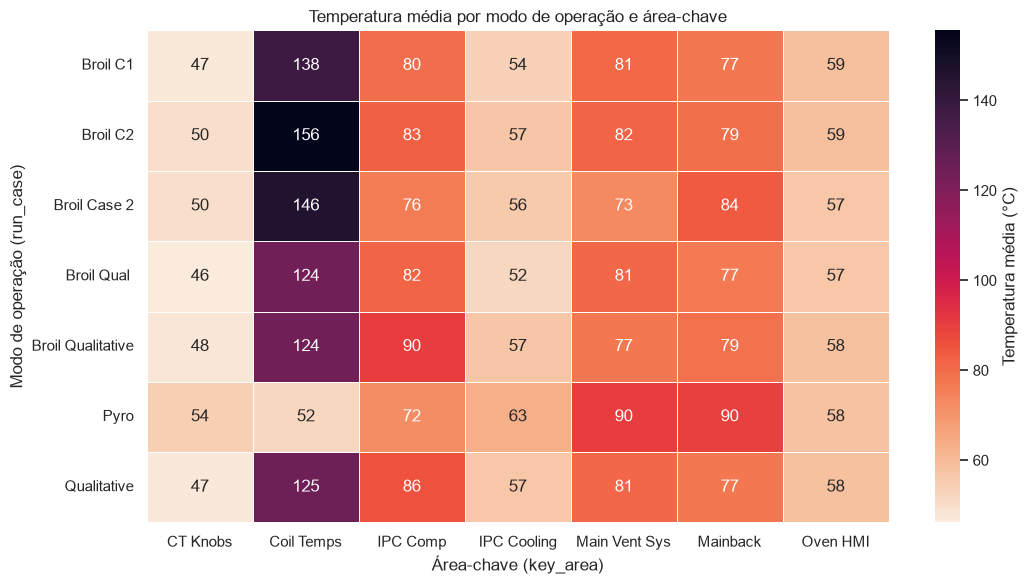

In [6]:
pivot = df.pivot_table(index='run_case', columns='key_area', values='temp', aggfunc='mean')

fig, ax = plt.subplots(figsize=(11, 6))
sns.heatmap(pivot, annot=True, fmt='.0f', cmap='rocket_r', linewidths=0.5, ax=ax,
            cbar_kws={'label': 'Temperatura média (°C)'})
ax.set_xlabel('Área-chave (key_area)')
ax.set_ylabel('Modo de operação (run_case)')
ax.set_title('Temperatura média por modo de operação e área-chave')
plt.tight_layout()
plt.savefig(f'{FIG_DIR}/temp_heatmap_runcase_area.png', dpi=150)
plt.show()

## 7. Gráfico 5 — % de leituras que excedem o limite por área-chave

Bar chart com o percentual de leituras que excedem o `active_limit`, por `key_area` — a mesma base (`plot_df`) do Gráfico 3, agregada em uma métrica direta de risco em vez de um scatter. Complementa o Gráfico 1 (que mostra a distribuição de temperatura por área, mas não diz nada sobre o limite de cada sensor).


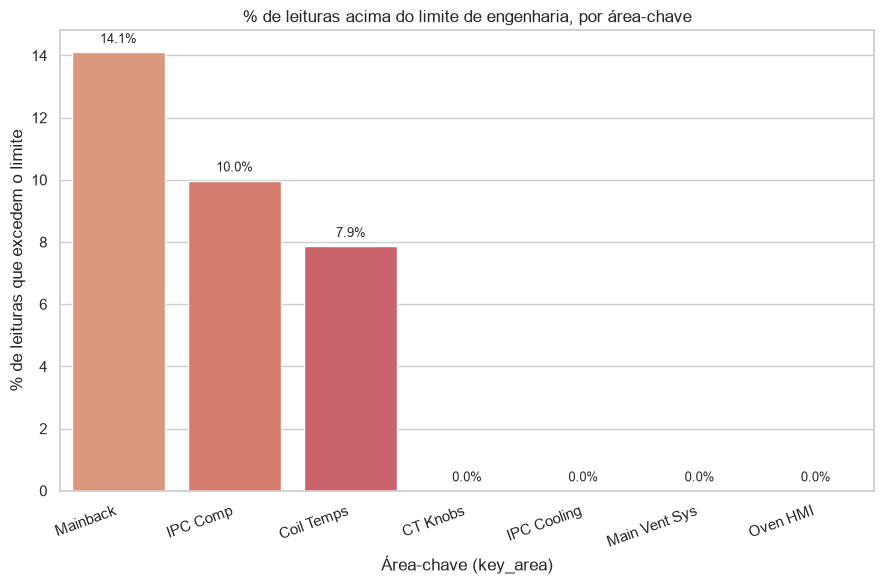

In [7]:
exceeds_area = (
    plot_df.groupby('key_area')['exceeds'].mean().mul(100).sort_values(ascending=False)
)

fig, ax = plt.subplots(figsize=(9, 6))
sns.barplot(x=exceeds_area.index, y=exceeds_area.values, hue=exceeds_area.index,
            palette='flare', legend=False, ax=ax)
for i, v in enumerate(exceeds_area.values):
    ax.text(i, v + 0.3, f'{v:.1f}%', ha='center', fontsize=9)
ax.set_xlabel('Área-chave (key_area)')
ax.set_ylabel('% de leituras que excedem o limite')
ax.set_title('% de leituras acima do limite de engenharia, por área-chave')
plt.xticks(rotation=20, ha='right')
plt.tight_layout()
plt.savefig(f'{FIG_DIR}/exceeds_por_area.png', dpi=150)
plt.show()

## 8. Gráfico 6 — % de leituras que excedem o limite por material do suporte da bobina

`material_coil_support` é citada na Seção 4.2.1 da documentação como variável central de uma das hipóteses de negócio do projeto (Seção 4.2.3). A temperatura média bruta por material é quase igual entre as 3 categorias (~80–83°C — pouco informativo em boxplot), mas a % de leituras que excedem o limite do próprio sensor já separa bem os grupos, porque o limite de engenharia também varia por sensor. Por isso o gráfico usa a métrica de excedência, não a temperatura crua.


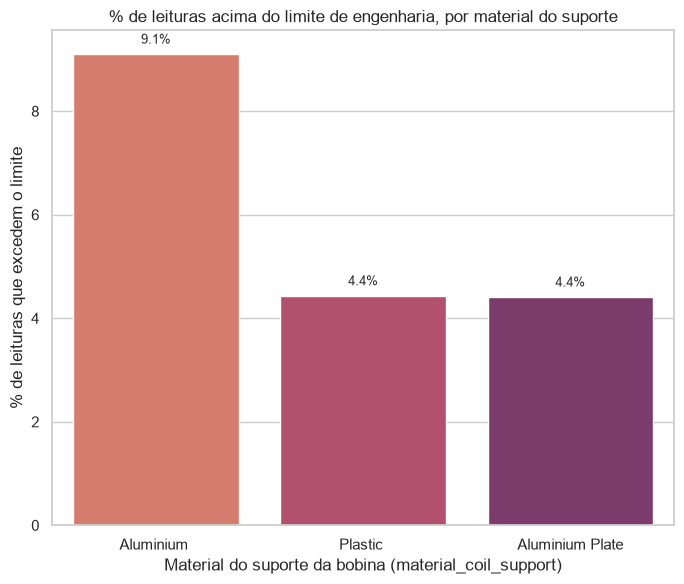

In [8]:
exceeds_material = (
    plot_df.groupby('material_coil_support')['exceeds'].mean().mul(100).sort_values(ascending=False)
)

fig, ax = plt.subplots(figsize=(7, 6))
sns.barplot(x=exceeds_material.index, y=exceeds_material.values, hue=exceeds_material.index,
            palette='flare', legend=False, ax=ax)
for i, v in enumerate(exceeds_material.values):
    ax.text(i, v + 0.2, f'{v:.1f}%', ha='center', fontsize=9)
ax.set_xlabel('Material do suporte da bobina (material_coil_support)')
ax.set_ylabel('% de leituras que excedem o limite')
ax.set_title('% de leituras acima do limite de engenharia, por material do suporte')
plt.tight_layout()
plt.savefig(f'{FIG_DIR}/exceeds_por_material.png', dpi=150)
plt.show()

## 9. Gráfico 7 — % de leituras que excedem o limite por modo de operação

Mesma métrica de excedência, agora por `run_case`. Complementa o Gráfico 4 (heatmap de temperatura média por modo x área), traduzindo o mapa térmico em uma métrica de risco direta por modo de operação.


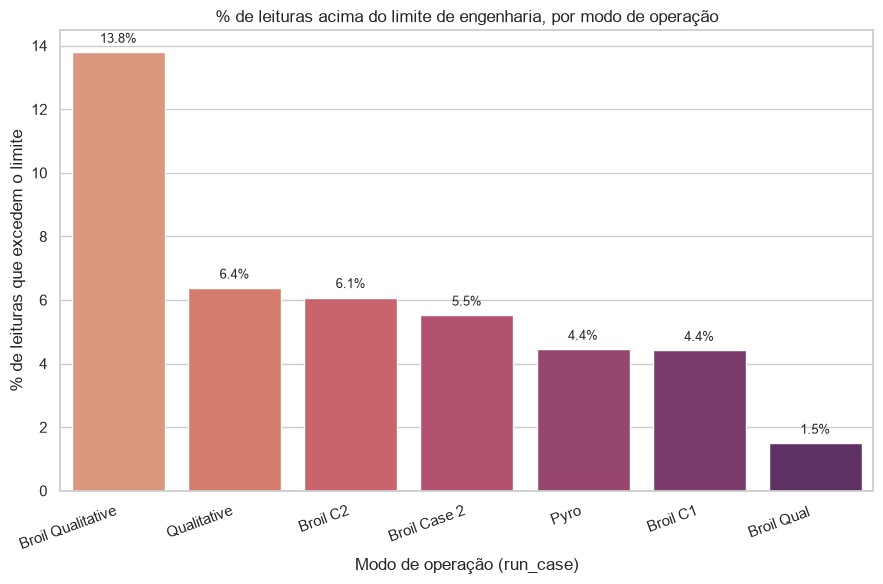

In [9]:
exceeds_runcase = (
    plot_df.groupby('run_case')['exceeds'].mean().mul(100).sort_values(ascending=False)
)

fig, ax = plt.subplots(figsize=(9, 6))
sns.barplot(x=exceeds_runcase.index, y=exceeds_runcase.values, hue=exceeds_runcase.index,
            palette='flare', legend=False, ax=ax)
for i, v in enumerate(exceeds_runcase.values):
    ax.text(i, v + 0.3, f'{v:.1f}%', ha='center', fontsize=9)
ax.set_xlabel('Modo de operação (run_case)')
ax.set_ylabel('% de leituras que excedem o limite')
ax.set_title('% de leituras acima do limite de engenharia, por modo de operação')
plt.xticks(rotation=20, ha='right')
plt.tight_layout()
plt.savefig(f'{FIG_DIR}/exceeds_por_runcase.png', dpi=150)
plt.show()

## 10. Síntese

Os 7 gráficos acima cobrem a exigência mínima de 3 visualizações da Seção 4.2.1, usando apenas colunas com variância confirmada na classificação de colunas ([`data/classificacao_colunas.csv`](../data/classificacao_colunas.csv)):

1. **`temp` x `key_area`** — regimes térmicos distintos por área física.
2. **`temp` x `housing` x `blower_direction`** — interação entre carcaça e direção do ar.
3. **`temp` x `active_limit`** — quantifica o problema de negócio central: % de leituras que excedem o limite de engenharia.
4. **`temp` x `run_case` x `key_area`** — como o modo de operação redefine o mapa térmico por área.
5. **% excede limite x `key_area`** — 100% dos estouros do dataset ocorrem em só 3 das 7 áreas (`Mainback`, `IPC Comp`, `Coil Temps`); as outras 4 nunca excedem.
6. **% excede limite x `material_coil_support`** — suporte de alumínio excede quase 2x mais que plástico (9,1% vs. 4,4%), apesar da temperatura média bruta ser parecida entre os materiais; testa diretamente a hipótese citada na Seção 4.2.1/4.2.3.
7. **% excede limite x `run_case`** — `Broil Qualitative` excede em 13,8% dos casos, bem acima dos demais modos (1,5%–6,4%).

Imagens salvas em [`assets/graficos/`](../assets/graficos/) e referenciadas na Seção 4.2.1 de [`documentacao.md`](../documents/documentacao.md).
